In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt, colors, patches

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/data_exploration/manifold/../../utils/train_utils.py'>

In [3]:
selection_n = ['DD01', 'VB02', 'AVAR', 'ALA']  # 'DB01',
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 3
dims_preca = 5

plot_id = 19

In [4]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# remove unused discrete state labels
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [5]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[ds[selection_bhl] for ds in discrete_states],
																	n_cv=dims, n_pc=dims_preca)

In [26]:
for file_id in range(len(file_ids)):
	corrs = [
		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV {i}: {corr:.2f}')

2022-11-23_worm10
	CV 0: 0.80
	CV 1: 0.24
	CV 2: 0.06
2022-11-23_worm11
	CV 0: 0.85
	CV 1: 0.32
	CV 2: 0.25
2022-11-23_worm12
	CV 0: 0.76
	CV 1: 0.21
	CV 2: 0.16
2022-11-23_worm8
	CV 0: 0.75
	CV 1: 0.30
	CV 2: 0.12
2022-11-23_worm9
	CV 0: 0.74
	CV 1: 0.19
	CV 2: 0.07
2023-11-21_12-39_wt_worm1-2023-11-21
	CV 0: 0.70
	CV 1: 0.36
	CV 2: 0.30
2023-11-21_14-28_wt_worm3-2023-11-21
	CV 0: 0.78
	CV 1: 0.37
	CV 2: 0.06
2023-11-21_14-46_wt_worm4-2023-11-21
	CV 0: 0.80
	CV 1: 0.67
	CV 2: 0.28
2023-11-21_15-05_wt_worm5-2023-11-21
	CV 0: 0.86
	CV 1: 0.41
	CV 2: 0.12
2023-11-30_13-58_wt_worm3_FM-2023-11-30
	CV 0: 0.81
	CV 1: 0.53
	CV 2: 0.27
2023-11-30_14-31_wt_worm5_FM-2023-11-30
	CV 0: 0.74
	CV 1: 0.25
	CV 2: 0.13
2023-12-19_17-35_wt_FM_worm4-2023-12-19
	CV 0: 0.75
	CV 1: 0.21
	CV 2: 0.18
2023-12-19_18-27_wt_FM_worm5again2-2023-12-19
	CV 0: 0.80
	CV 1: 0.36
	CV 2: 0.26
2024-01-11_16-42_wt_FM_worm06-2024-01-11
	CV 0: 0.75
	CV 1: 0.28
	CV 2: 0.13
2024-01-17_13-02_wt_FM_worm2_again-2024-01-17
	CV 0: 

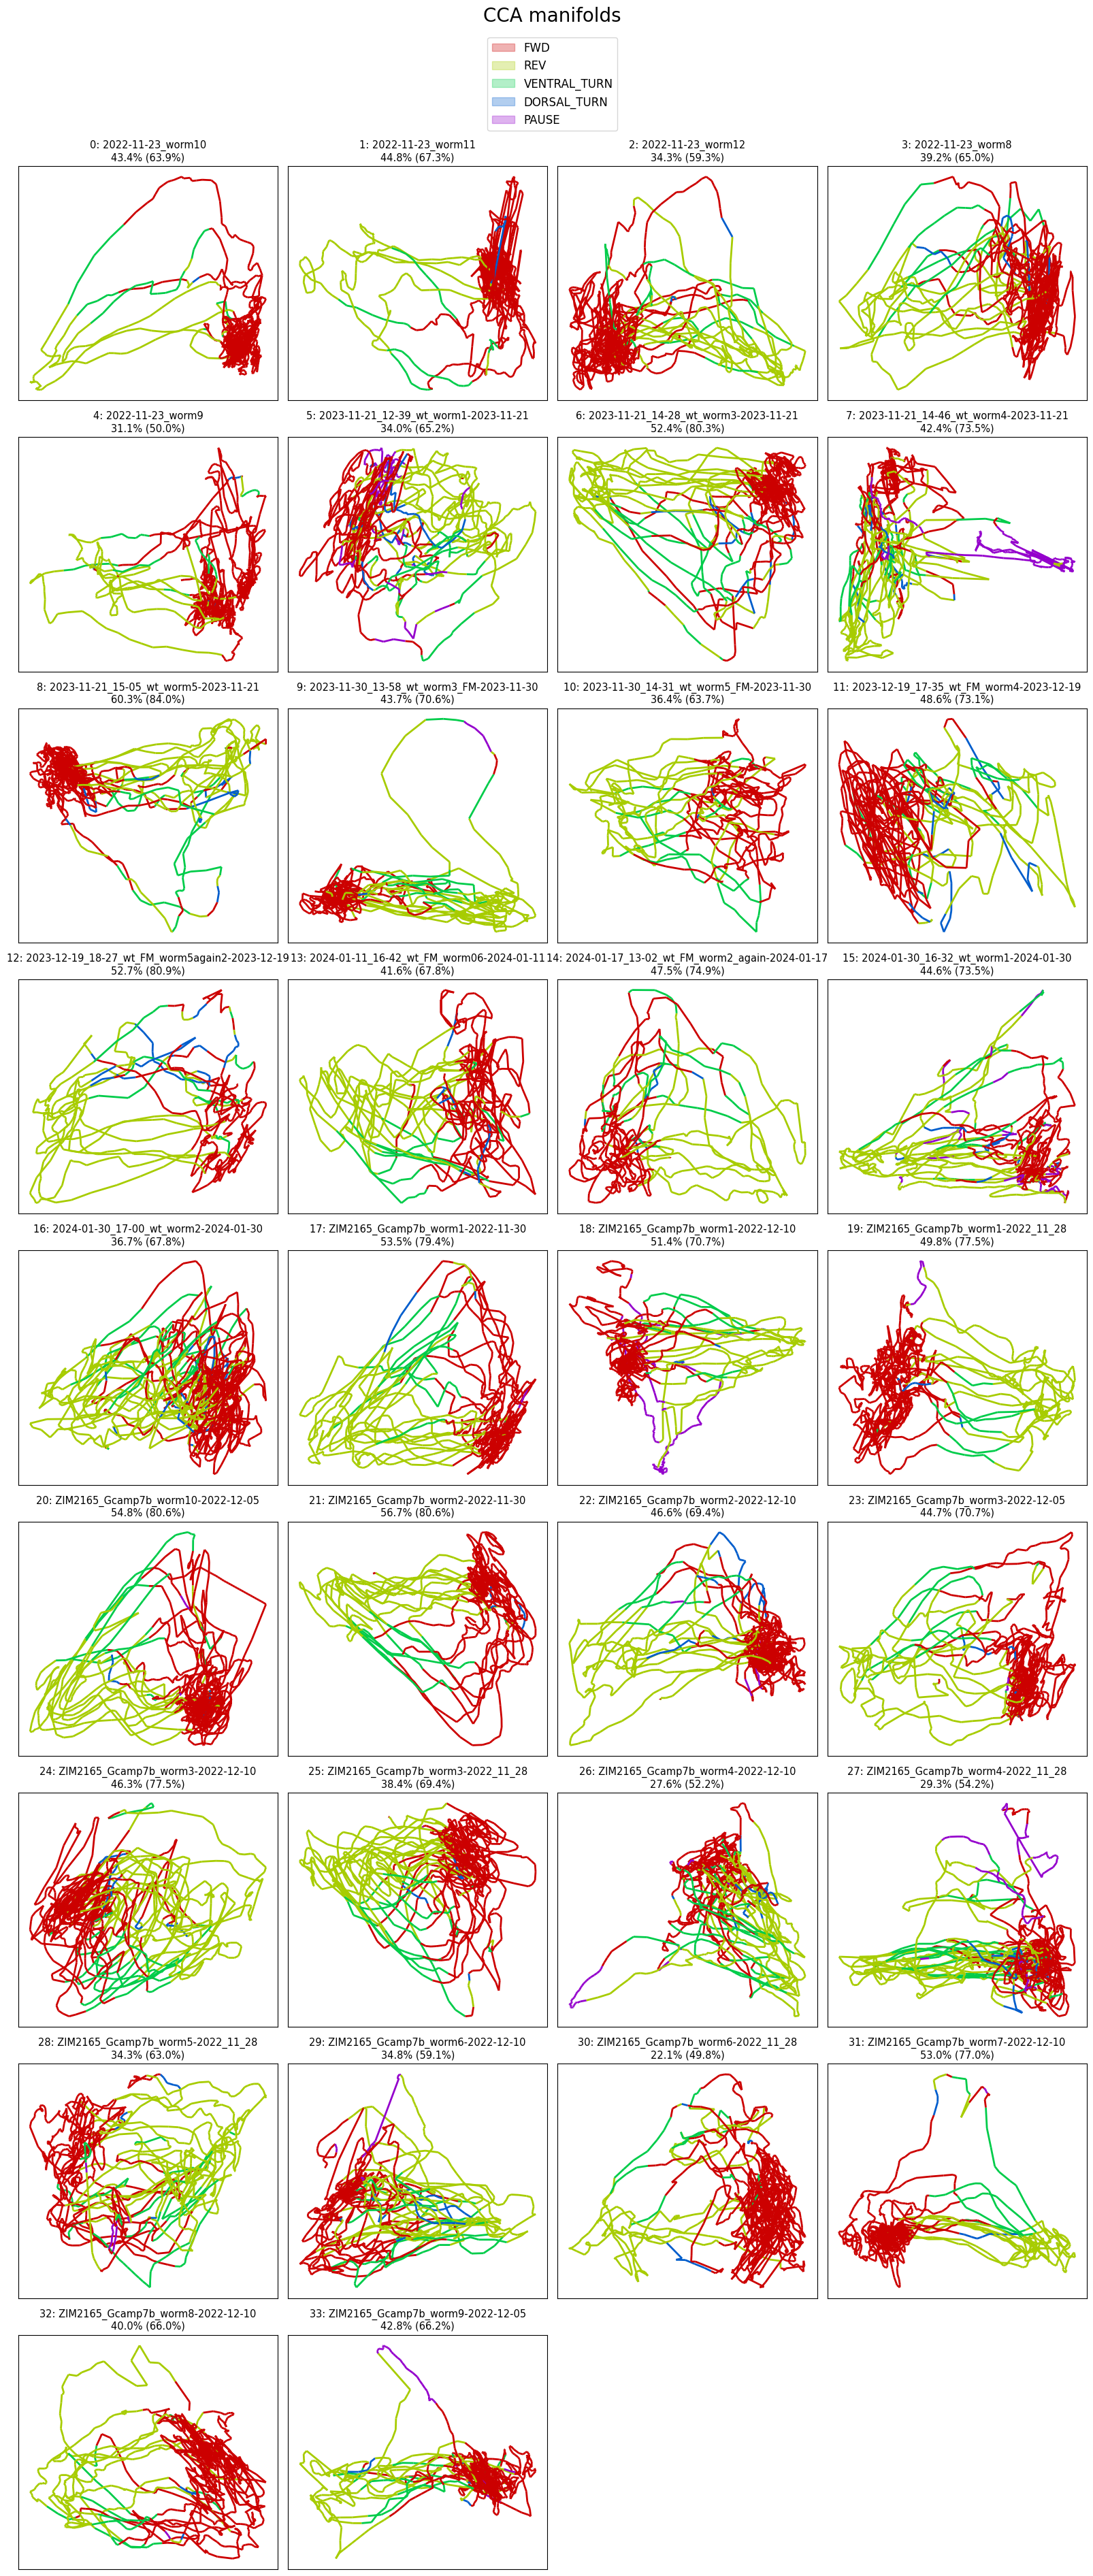

42.9% (34.5%)


In [7]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds', save_name=None)  #f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA'

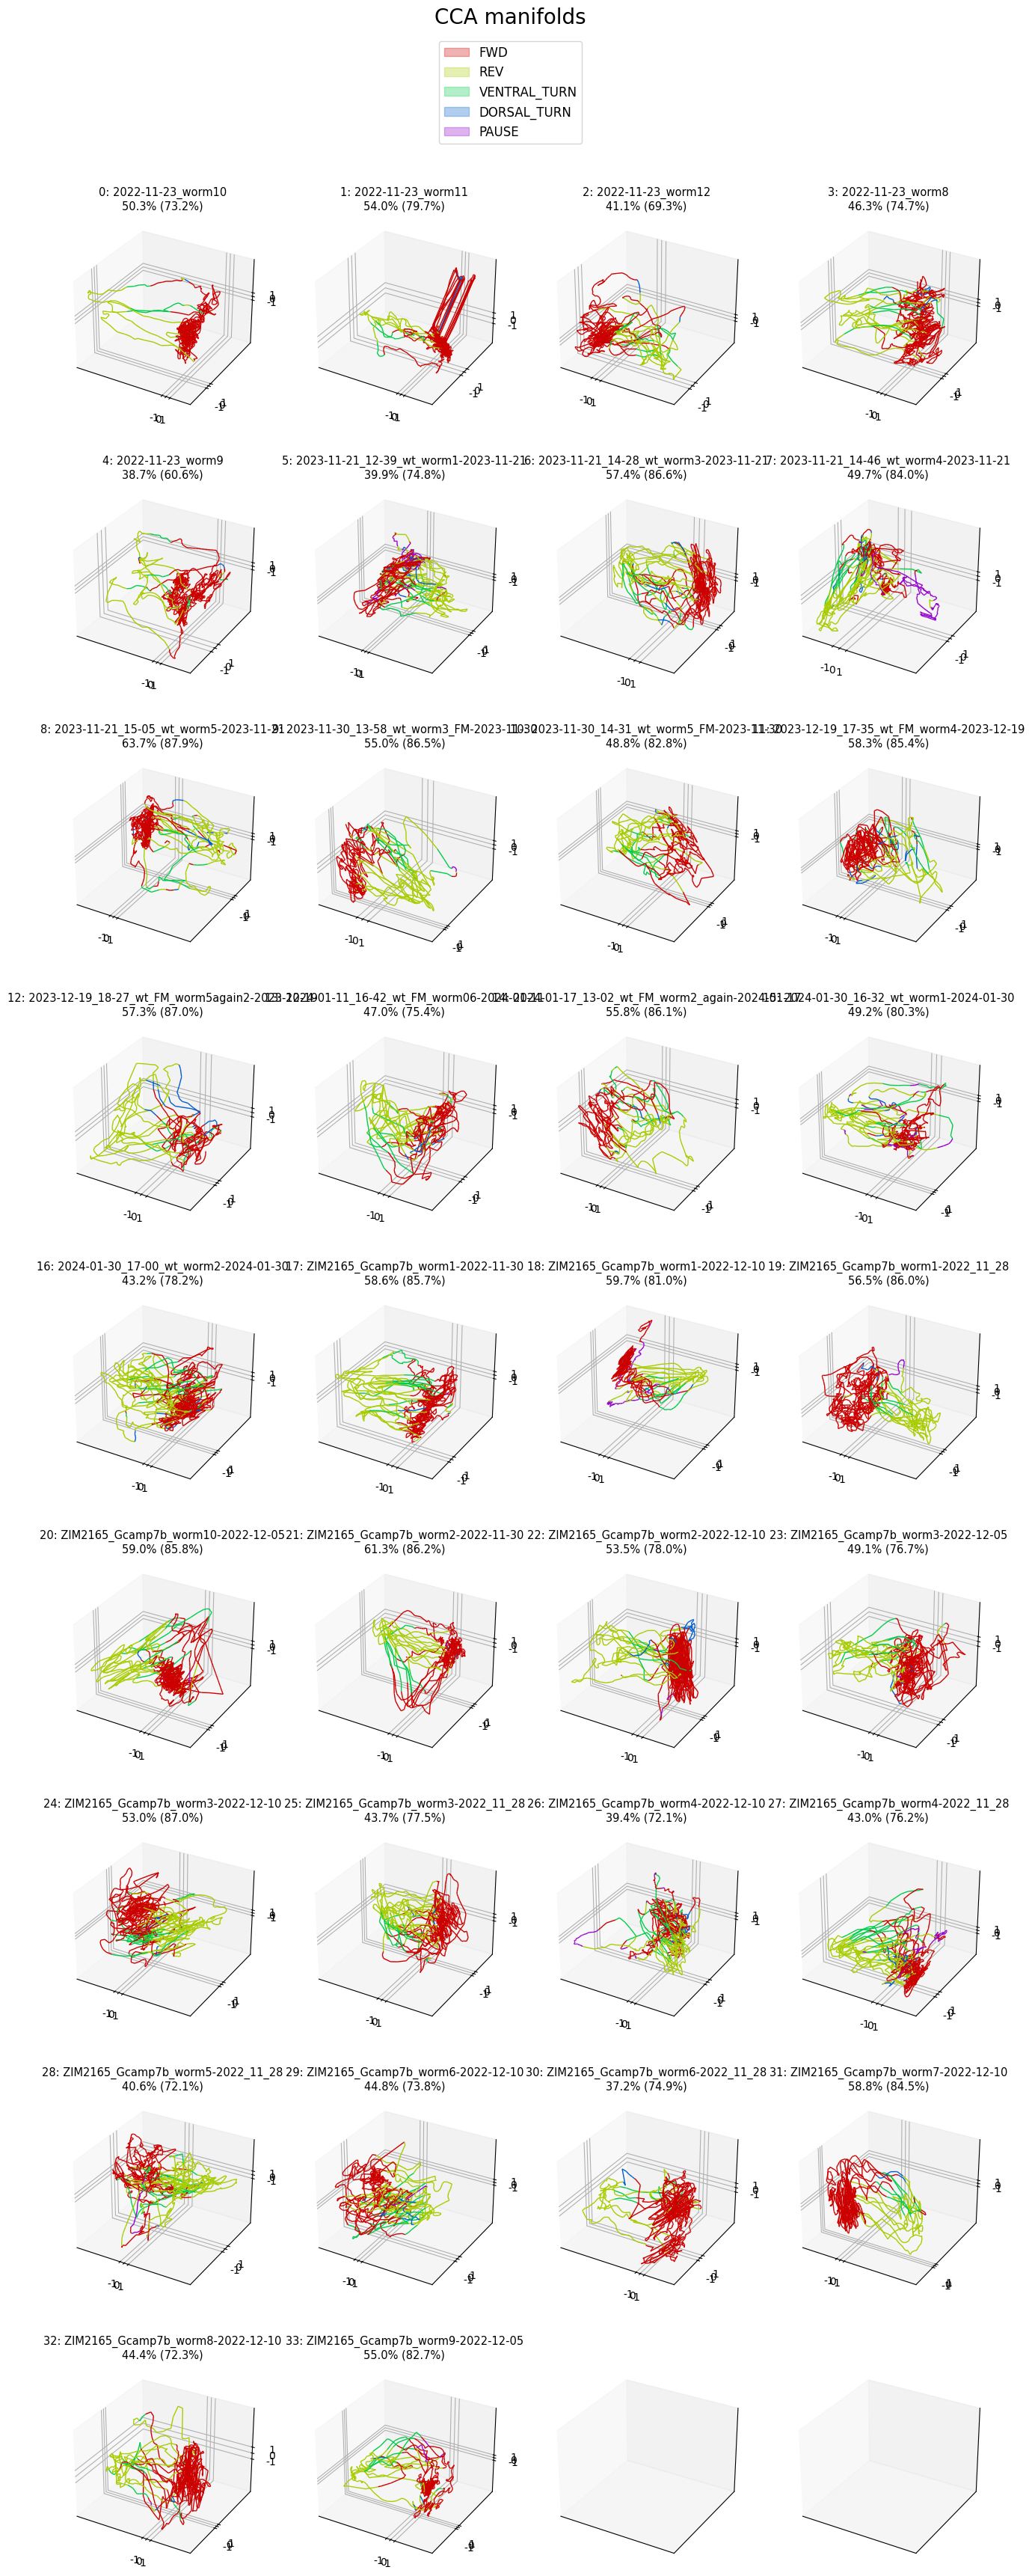

50.4% (26.5%)


In [8]:
plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
							 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
							 title='CCA manifolds', save_name=None)  #f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d'

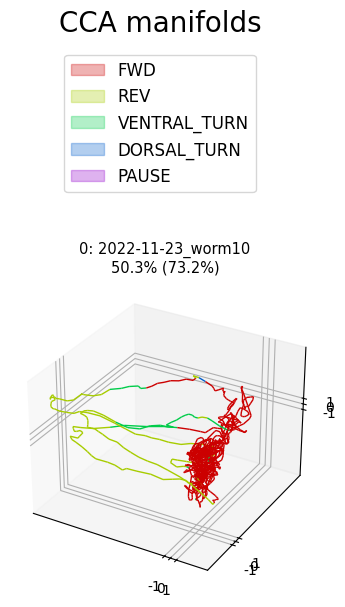

50.3% (24.4%)


In [9]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
								 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
								 animate=True, n_plots=1,
								 titles=['CCA manifolds'] * len(file_ids), save_name=None)  #f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d'

In [12]:
for i, trace in enumerate([t.values - t_rec.values for t, t_rec in zip(traces, recos_manifold)]):
	print(np.median(trace, axis=0))

[-2.45057593e-03  2.54321193e-02  9.66398868e-04  2.04169671e-03
 -1.64153233e-03 -6.39473382e-03  7.64991783e-04  1.32351705e-03
  1.25293771e-02 -6.30020432e-03 -6.48648650e-03 -3.94868514e-02
 -6.39759309e-03 -2.02794408e-03 -9.34205510e-03  2.08000770e-03
 -4.05313533e-04 -1.55637297e-02 -2.13391895e-03 -9.11499846e-04
  2.40769562e-03  8.56121942e-04  1.40849229e-03 -6.08929394e-03
 -7.34935071e-03  2.32938574e-03  1.81999557e-03  8.58157538e-04
  1.72481804e-03  1.27626358e-02 -7.64165713e-04 -4.99925591e-04
  1.53345750e-03 -3.10024068e-03  3.79997065e-04 -1.13797315e-03
 -2.65037844e-03 -2.31519827e-03  2.20106697e-03 -2.06324260e-04
 -4.64348335e-03 -2.59490868e-03 -4.22281599e-04 -3.05812769e-03
 -4.03977660e-04 -3.67240809e-02 -7.13991659e-03 -4.12750794e-03
  9.86188172e-04  4.02883483e-03  2.45898602e-04 -2.42805531e-03
 -5.83603082e-04  7.90907273e-03 -2.13087996e-03  3.29903812e-03
  4.76191588e-03 -4.13063979e-03  5.64576862e-03  1.74314641e-03
 -8.50040581e-04 -7.31023

In [ ]:
# traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recos_manifold)]
#
# plot_utils.plot_traces('residuals',
# 					   discrete_states[file_ids.index(plot_id)]['REV'],
# 					   traces_residual[file_ids.index(plot_id)][selection_n],
# 					   n_plots=None, plots_per_row=1, ylimits=None)